<a href="https://colab.research.google.com/github/srirammulukuntla11/AIEC/blob/main/aiec_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXERCISE 10: ADAPTIVE RESONANCE THEORY (ART)
DYNAMIC CATEGORY FORMATION AND NOVEL PATTERN DISCOVERY

Attempting dataset download: https://archive.ics.uci.edu/ml/machine-learning-databases/00602/DryBeanDataset/Dry_Bean_Dataset.xlsx
Download attempt failed: HTTP Error 404: Not Found

Attempting dataset download: https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip
Real Dry Bean Dataset loaded successfully.

Dataset summary
-----------------------------------------------------------------
Dataset source: UCI Dry Bean
Number of samples: 13611
Number of numerical features: 16
Number of varieties/classes: 7
Varieties: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Feature normalization: Min-Max scaling to [0, 1]
ART model: Fuzzy ART with complement coding

                EXERCISE 10 - FUZZY ART NETWORK
1. Incremental Bean Category Formation
2. Vigilance Parameter Challenge
3. Resonance and Reset Analyzer
4. Novel Bean Pattern Detector
5. Category Split an

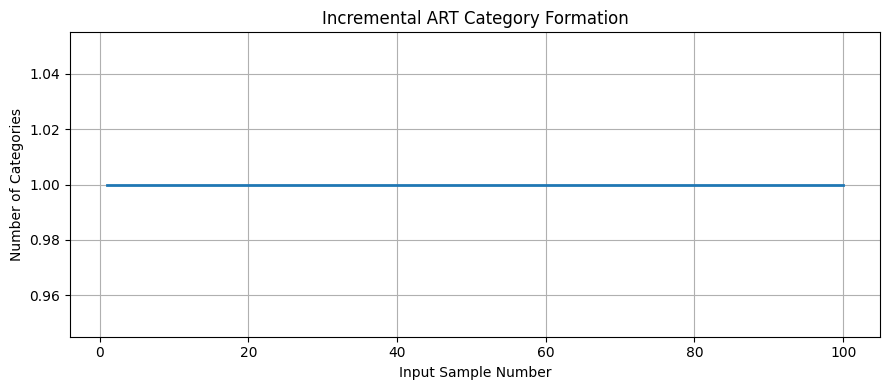


                EXERCISE 10 - FUZZY ART NETWORK
1. Incremental Bean Category Formation
2. Vigilance Parameter Challenge
3. Resonance and Reset Analyzer
4. Novel Bean Pattern Detector
5. Category Split and Merge Explorer
6. Catastrophic Forgetting Resistance Test
7. Input Order Sensitivity Challenge
8. ART Category Formation Report
9. Exit



In [ ]:
# =====================================================================
# Exercise 10: Apply Adaptive Resonance Theory (ART) for Dynamic
# Category Formation and Novel Pattern Discovery using the Dry Bean Dataset
# =====================================================================

import os
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.datasets import make_classification

warnings.filterwarnings("ignore")
np.random.seed(42)

print("=" * 85)
print("EXERCISE 10: ADAPTIVE RESONANCE THEORY (ART)")
print("DYNAMIC CATEGORY FORMATION AND NOVEL PATTERN DISCOVERY")
print("=" * 85)


# =====================================================================
# 1. DATASET LOADING
# =====================================================================

def load_dry_bean_dataset():
    """
    Load the Dry Bean Dataset from UCI.
    If network access is unavailable, use a clearly labelled
    synthetic demonstration dataset.
    """

    urls = [
        "https://archive.ics.uci.edu/ml/machine-learning-databases/00602/DryBeanDataset/Dry_Bean_Dataset.xlsx",
        "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
    ]

    for url in urls:
        try:
            print("\nAttempting dataset download:", url)

            if url.endswith(".xlsx"):
                df = pd.read_excel(url)
            else:
                import zipfile
                import io
                with urllib.request.urlopen(url, timeout=15) as response:
                    content = response.read()

                with zipfile.ZipFile(io.BytesIO(content)) as archive:
                    excel_name = next(
                        name for name in archive.namelist()
                        if name.lower().endswith(".xlsx")
                    )
                    with archive.open(excel_name) as file:
                        df = pd.read_excel(file)

            if "Class" not in df.columns:
                continue

            print("Real Dry Bean Dataset loaded successfully.")
            return df, True

        except Exception as e:
            print("Download attempt failed:", str(e)[:120])

    print("\nWARNING: Real dataset could not be downloaded.")
    print("Creating a synthetic demonstration dataset instead.")

    X, y = make_classification(
        n_samples=1200,
        n_features=16,
        n_informative=12,
        n_redundant=2,
        n_classes=7,
        n_clusters_per_class=1,
        class_sep=1.3,
        random_state=42
    )

    feature_names = [
        "Area", "Perimeter", "MajorAxisLength", "MinorAxisLength",
        "AspectRation", "Eccentricity", "ConvexArea", "EquivDiameter",
        "Extent", "Solidity", "roundness", "Compactness",
        "ShapeFactor1", "ShapeFactor2", "ShapeFactor3", "ShapeFactor4"
    ]

    df = pd.DataFrame(X, columns=feature_names)
    class_names = [
        "BARBUNYA", "BOMBAY", "CALI", "DERMASON",
        "HOROZ", "SEKER", "SIRA"
    ]
    df["Class"] = [class_names[int(i)] for i in y]

    return df, False


df, is_real_dataset = load_dry_bean_dataset()

feature_columns = [
    column for column in df.columns
    if column != "Class" and pd.api.types.is_numeric_dtype(df[column])
]

df = df.dropna(subset=feature_columns + ["Class"]).reset_index(drop=True)

X_raw = df[feature_columns].values.astype(float)
y_labels = df["Class"].astype(str).values

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_raw)

# Avoid exact all-zero vectors, which can be problematic for
# complement-coded inputs in some ART implementations.
X_scaled = np.clip(X_scaled, 0, 1)

class_names = sorted(np.unique(y_labels))
class_to_id = {name: i for i, name in enumerate(class_names)}
y = np.array([class_to_id[name] for name in y_labels])

print("\nDataset summary")
print("-" * 65)
print("Dataset source:", "UCI Dry Bean" if is_real_dataset else "Synthetic demonstration data")
print("Number of samples:", len(X_scaled))
print("Number of numerical features:", X_scaled.shape[1])
print("Number of varieties/classes:", len(class_names))
print("Varieties:", class_names)
print("Feature normalization: Min-Max scaling to [0, 1]")
print("ART model: Fuzzy ART with complement coding")


# =====================================================================
# 2. FUZZY ART NEURAL NETWORK
# =====================================================================

class FuzzyART:
    """
    Fuzzy ART with:
      - Complement coding
      - Choice function
      - Vigilance test
      - Resonance and reset
      - Online prototype updates

    Parameters
    ----------
    vigilance : float
        Minimum match value required for resonance.
    alpha : float
        Choice parameter, alpha > 0.
    beta : float
        Learning rate, where beta=1 gives fast learning.
    """

    def __init__(self, vigilance=0.75, alpha=0.001, beta=1.0):
        self.vigilance = float(vigilance)
        self.alpha = float(alpha)
        self.beta = float(beta)

        self.weights = []
        self.category_sizes = []
        self.resonance_count = 0
        self.reset_count = 0
        self.assignment_history = []
        self.search_history = []

    @staticmethod
    def fuzzy_and(a, b):
        return np.minimum(a, b)

    def complement_code(self, x):
        x = np.clip(np.asarray(x, dtype=float), 0, 1)
        return np.concatenate([x, 1 - x])

    def choice_value(self, input_vector, weight):
        numerator = np.sum(self.fuzzy_and(input_vector, weight))
        denominator = self.alpha + np.sum(weight)
        return numerator / denominator

    def match_value(self, input_vector, weight):
        numerator = np.sum(self.fuzzy_and(input_vector, weight))
        denominator = np.sum(input_vector)

        if denominator <= 1e-12:
            return 0.0

        return numerator / denominator

    def fit_one(self, x, sample_number=None):
        """
        Present one sample to the network.

        A category is selected by the largest choice value.
        If its match value is below vigilance, it is reset and
        the search continues with the next category.
        If no category resonates, create a new category.
        """

        I = self.complement_code(x)
        rejected = set()
        sequence = []

        while True:
            available = [
                j for j in range(len(self.weights))
                if j not in rejected
            ]

            if not available:
                self.weights.append(I.copy())
                self.category_sizes.append(1)
                category = len(self.weights) - 1

                self.resonance_count += 1
                sequence.append({
                    "Category": category + 1,
                    "Choice": np.nan,
                    "Match": 1.0,
                    "Status": "NEW CATEGORY"
                })

                break

            choice_values = {
                j: self.choice_value(I, self.weights[j])
                for j in available
            }

            winner = max(choice_values, key=choice_values.get)
            match = self.match_value(I, self.weights[winner])
            choice = choice_values[winner]

            if match >= self.vigilance:
                # Resonance: update the prototype.
                self.weights[winner] = (
                    self.beta * self.fuzzy_and(I, self.weights[winner])
                    + (1 - self.beta) * self.weights[winner]
                )

                self.category_sizes[winner] += 1
                self.resonance_count += 1

                sequence.append({
                    "Category": winner + 1,
                    "Choice": choice,
                    "Match": match,
                    "Status": "RESONANCE"
                })

                category = winner
                break

            # Vigilance failed: reset the current category.
            sequence.append({
                "Category": winner + 1,
                "Choice": choice,
                "Match": match,
                "Status": "RESET"
            })

            rejected.add(winner)
            self.reset_count += 1

        self.assignment_history.append(category)

        self.search_history.append({
            "Sample": sample_number,
            "Category": category + 1,
            "Match": sequence[-1]["Match"],
            "Search Sequence": sequence
        })

        return category, sequence

    def fit(self, X):
        self.weights = []
        self.category_sizes = []
        self.resonance_count = 0
        self.reset_count = 0
        self.assignment_history = []
        self.search_history = []

        for i, x in enumerate(X):
            self.fit_one(x, sample_number=i + 1)

        return self

    def predict_one(self, x):
        """
        Assign a sample to the best existing category without
        updating prototypes or creating a new category.
        Return -1 if no category satisfies vigilance.
        """

        I = self.complement_code(x)
        candidates = sorted(
            range(len(self.weights)),
            key=lambda j: self.choice_value(I, self.weights[j]),
            reverse=True
        )

        for j in candidates:
            match = self.match_value(I, self.weights[j])

            if match >= self.vigilance:
                return j, match

        return -1, 0.0

    def assign_or_create(self, x, sample_number=None):
        return self.fit_one(x, sample_number=sample_number)

    def category_sizes_now(self):
        return list(self.category_sizes)

    def category_count(self):
        return len(self.weights)


def category_distribution(assignments):
    values, counts = np.unique(assignments, return_counts=True)
    return {int(k) + 1: int(v) for k, v in zip(values, counts)}


def create_art(vigilance=0.75):
    return FuzzyART(vigilance=vigilance, alpha=0.001, beta=1.0)


def ensure_reasonable_subset(max_samples=1200):
    """
    Use a reproducible subset for faster menu-driven experiments.
    """
    if len(X_scaled) <= max_samples:
        return X_scaled, y_labels

    rng = np.random.default_rng(42)
    indices = np.sort(
        rng.choice(len(X_scaled), size=max_samples, replace=False)
    )

    return X_scaled[indices], y_labels[indices]


X, labels = ensure_reasonable_subset(max_samples=1200)


# =====================================================================
# 3. MENU OPTION 1: INCREMENTAL BEAN CATEGORY FORMATION
# =====================================================================

def option_1():
    print("\n" + "=" * 75)
    print("1. INCREMENTAL BEAN CATEGORY FORMATION")
    print("=" * 75)

    try:
        vigilance = float(
            input("Enter vigilance parameter (0.1 to 0.99, default 0.75): ")
            or "0.75"
        )
        vigilance = float(np.clip(vigilance, 0.1, 0.99))
    except ValueError:
        vigilance = 0.75

    try:
        n = int(input(f"Number of samples to train (1-{len(X)}, default 100): ") or "100")
        n = int(np.clip(n, 1, len(X)))
    except ValueError:
        n = min(100, len(X))

    art = create_art(vigilance)

    rows = []

    for i, x in enumerate(X[:n]):
        category, sequence = art.fit_one(x, sample_number=i + 1)

        rows.append({
            "Sample": i + 1,
            "True Variety": labels[i],
            "Winning Category": category + 1,
            "Match Value": sequence[-1]["Match"],
            "Resonance Status": sequence[-1]["Status"],
            "Total Categories": art.category_count()
        })

    result = pd.DataFrame(rows)

    print("\nIncremental category formation results:")
    print(result.head(30).to_string(index=False))

    if len(result) > 30:
        print(f"\nShowing first 30 of {len(result)} samples.")

    print("\nFinal number of categories:", art.category_count())
    print("Total resonance events:", art.resonance_count)
    print("Total reset events:", art.reset_count)
    print("Category sizes:", category_distribution(art.assignment_history))

    plt.figure(figsize=(9, 4))
    plt.plot(
        result["Sample"],
        result["Total Categories"],
        linewidth=2
    )
    plt.title("Incremental ART Category Formation")
    plt.xlabel("Input Sample Number")
    plt.ylabel("Number of Categories")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# =====================================================================
# 4. MENU OPTION 2: VIGILANCE PARAMETER CHALLENGE
# =====================================================================

def option_2():
    print("\n" + "=" * 75)
    print("2. VIGILANCE PARAMETER CHALLENGE")
    print("=" * 75)

    vigilance_values = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
    sample_count = min(500, len(X))

    rows = []
    size_distributions = {}

    for vigilance in vigilance_values:
        art = create_art(vigilance)
        art.fit(X[:sample_count])

        sizes = category_distribution(art.assignment_history)
        size_distributions[vigilance] = sizes

        rows.append({
            "Vigilance": vigilance,
            "Samples": sample_count,
            "Categories Created": art.category_count(),
            "Resonance Count": art.resonance_count,
            "Reset Count": art.reset_count,
            "Largest Category": max(sizes.values()) if sizes else 0,
            "Smallest Category": min(sizes.values()) if sizes else 0
        })

    result = pd.DataFrame(rows)

    print("\nVigilance comparison:")
    print(result.to_string(index=False))

    print("\nCategory sizes for each vigilance:")
    for vigilance, sizes in size_distributions.items():
        print(f"\nVigilance = {vigilance}: {sizes}")

    print(
        "\nInterpretation: low vigilance generally allows broader matching; "
        "high vigilance demands closer matches and often creates more categories."
    )

    print(
        "Meaningful structure should be judged using domain knowledge, "
        "category sizes, and class composition rather than category count alone."
    )

    plt.figure(figsize=(8, 5))
    plt.plot(
        result["Vigilance"],
        result["Categories Created"],
        marker="o"
    )
    plt.title("Vigilance vs. Number of ART Categories")
    plt.xlabel("Vigilance Parameter")
    plt.ylabel("Categories Created")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# =====================================================================
# 5. MENU OPTION 3: RESONANCE AND RESET ANALYZER
# =====================================================================

def option_3():
    print("\n" + "=" * 75)
    print("3. RESONANCE AND RESET ANALYZER")
    print("=" * 75)

    try:
        vigilance = float(input("Enter vigilance (default 0.80): ") or "0.80")
        vigilance = float(np.clip(vigilance, 0.1, 0.99))
    except ValueError:
        vigilance = 0.80

    art = create_art(vigilance)
    n = min(100, len(X))
    art.fit(X[:n])

    try:
        sample_index = int(input(f"Choose sample number (1-{n}): ") or "1")
        sample_index = int(np.clip(sample_index, 1, n)) - 1
    except ValueError:
        sample_index = 0

    x = X[sample_index]
    I = art.complement_code(x)

    # Examine category search sequence without changing trained model.
    candidates = sorted(
        range(len(art.weights)),
        key=lambda j: art.choice_value(I, art.weights[j]),
        reverse=True
    )

    sequence_rows = []
    chosen = None

    for rank, j in enumerate(candidates, start=1):
        choice = art.choice_value(I, art.weights[j])
        match = art.match_value(I, art.weights[j])

        if match >= vigilance:
            status = "RESONANCE"
            chosen = j
        else:
            status = "RESET"

        sequence_rows.append({
            "Search Step": rank,
            "Category": j + 1,
            "Choice Value": round(choice, 4),
            "Match Value": round(match, 4),
            "Vigilance": vigilance,
            "Status": status
        })

        if chosen is not None:
            break

    if chosen is None:
        sequence_rows.append({
            "Search Step": len(sequence_rows) + 1,
            "Category": "New",
            "Choice Value": np.nan,
            "Match Value": 1.0,
            "Vigilance": vigilance,
            "Status": "NEW CATEGORY REQUIRED"
        })

    result = pd.DataFrame(sequence_rows)

    print("\nSelected sample:", sample_index + 1)
    print("True variety:", labels[sample_index])
    print("\nCategory-search sequence:")
    print(result.to_string(index=False))

    print("\nExplanation:")
    print("- Choice value ranks candidate categories.")
    print("- Match value is tested against vigilance.")
    print("- A failed vigilance test causes reset and search continues.")
    print("- The first category meeting vigilance resonates.")


# =====================================================================
# 6. MENU OPTION 4: NOVEL BEAN PATTERN DETECTOR
# =====================================================================

def option_4():
    print("\n" + "=" * 75)
    print("4. NOVEL BEAN PATTERN DETECTOR")
    print("=" * 75)

    varieties = sorted(np.unique(labels))

    print("\nAvailable varieties:", varieties)
    variety = input("Enter a variety to hold out (default first variety): ").strip()

    if variety not in varieties:
        variety = varieties[0]

    train_mask = labels != variety
    test_mask = labels == variety

    X_train = X[train_mask]
    labels_train = labels[train_mask]
    X_test = X[test_mask]

    if len(X_test) == 0:
        print("No samples found for selected variety.")
        return

    try:
        vigilance = float(input("Enter vigilance (default 0.80): ") or "0.80")
        vigilance = float(np.clip(vigilance, 0.1, 0.99))
    except ValueError:
        vigilance = 0.80

    train_n = min(700, len(X_train))
    test_n = min(20, len(X_test))

    art = create_art(vigilance)
    art.fit(X_train[:train_n])

    print(f"\nTrained on {train_n} samples excluding variety '{variety}'.")
    print(f"Testing {test_n} held-out samples from '{variety}'.")

    results = []

    for i, x in enumerate(X_test[:test_n]):
        category, match = art.predict_one(x)

        if category == -1:
            status = "Novel Pattern"
            new_category, seq = art.assign_or_create(
                x, sample_number=train_n + i + 1
            )
            category_to_report = new_category + 1
            action = "Created new category"

        else:
            # Compare with the category prototype's training membership.
            status = "Similar Pattern"
            category_to_report = category + 1
            action = "Assigned to existing category"

        results.append({
            "Test Sample": i + 1,
            "True Variety": variety,
            "Category": category_to_report,
            "Match Value": round(match, 4),
            "Classification": status,
            "Action": action
        })

    result = pd.DataFrame(results)

    print("\nNovel pattern detection results:")
    print(result.to_string(index=False))

    print("\nNote: a held-out class is not automatically guaranteed to")
    print("form new categories. The outcome depends on feature similarity")
    print("and the vigilance threshold.")


# =====================================================================
# 7. MENU OPTION 5: CATEGORY SPLIT AND MERGE EXPLORER
# =====================================================================

def option_5():
    print("\n" + "=" * 75)
    print("5. CATEGORY SPLIT AND MERGE EXPLORER")
    print("=" * 75)

    low_vigilance = 0.50
    high_vigilance_values = [0.60, 0.70, 0.80, 0.90, 0.95]
    sample_count = min(400, len(X))

    low_art = create_art(low_vigilance)
    low_art.fit(X[:sample_count])

    low_assignments = np.array(low_art.assignment_history)

    print("\nLow vigilance:", low_vigilance)
    print("Initial category count:", low_art.category_count())

    rows = []
    split_summary = []

    for high_vigilance in high_vigilance_values:
        high_art = create_art(high_vigilance)
        high_art.fit(X[:sample_count])

        high_assignments = np.array(high_art.assignment_history)

        rows.append({
            "Vigilance": high_vigilance,
            "Category Count": high_art.category_count(),
            "Resonance Count": high_art.resonance_count,
            "Reset Count": high_art.reset_count
        })

        split_mapping = {}

        for old_category in np.unique(low_assignments):
            indices = np.where(low_assignments == old_category)[0]
            new_categories = np.unique(high_assignments[indices])

            split_mapping[int(old_category) + 1] = [
                int(c) + 1 for c in new_categories
            ]

            if len(new_categories) > 1:
                split_summary.append({
                    "Low-Vigilance Category": int(old_category) + 1,
                    "High Vigilance": high_vigilance,
                    "New Categories": [int(c) + 1 for c in new_categories],
                    "Number of Split Categories": len(new_categories),
                    "Samples In Original Category": len(indices)
                })

        print(f"\nVigilance {high_vigilance}:")
        print("Category count:", high_art.category_count())
        print("Original-to-new category mapping:")
        print(split_mapping)

    result = pd.DataFrame(rows)

    print("\nCategory count as vigilance increases:")
    print(result.to_string(index=False))

    print("\nDetected category splits:")
    if split_summary:
        print(pd.DataFrame(split_summary).to_string(index=False))
    else:
        print("No split detected in the selected sample subset.")

    print(
        "\nFuzzy ART is generally not a conventional merge algorithm. "
        "Increasing vigilance is tested here by retraining the network; "
        "the resulting categories are compared with low-vigilance assignments."
    )

    plt.figure(figsize=(8, 5))
    plt.plot(
        result["Vigilance"],
        result["Category Count"],
        marker="o"
    )
    plt.title("Category Split Exploration")
    plt.xlabel("Vigilance Parameter")
    plt.ylabel("Category Count")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# =====================================================================
# 8. MENU OPTION 6: CATASTROPHIC FORGETTING RESISTANCE TEST
# =====================================================================

def option_6():
    print("\n" + "=" * 75)
    print("6. CATASTROPHIC FORGETTING RESISTANCE TEST")
    print("=" * 75)

    varieties = sorted(np.unique(labels))

    if len(varieties) < 3:
        print("Not enough varieties to run the phase experiment.")
        return

    rng = np.random.default_rng(42)
    shuffled_varieties = list(varieties)
    rng.shuffle(shuffled_varieties)

    phase_1 = shuffled_varieties[:2]
    phase_2 = shuffled_varieties[2:4]
    phase_3 = shuffled_varieties[4:]

    print("Phase 1 varieties:", phase_1)
    print("Phase 2 varieties:", phase_2)
    print("Phase 3 varieties:", phase_3)

    art = create_art(0.80)
    rows = []
    old_samples = []
    old_assignments = []

    phases = [phase_1, phase_2, phase_3]

    for phase_number, phase_varieties in enumerate(phases, start=1):
        phase_indices = [
            i for i, label in enumerate(labels)
            if label in phase_varieties
        ]

        phase_indices = phase_indices[:300]

        for idx in phase_indices:
            category, _ = art.fit_one(
                X[idx], sample_number=idx + 1
            )

        # Store samples and assignments after the current phase.
        if phase_number == 1:
            old_samples = [
                X[idx].copy() for idx in phase_indices[:50]
            ]
            old_assignments = [
                art.predict_one(sample)[0]
                for sample in old_samples
            ]

        if old_samples:
            retained = 0
            for sample, old_category in zip(
                old_samples, old_assignments
            ):
                new_category, _ = art.predict_one(sample)

                if new_category == old_category:
                    retained += 1

            retention = 100 * retained / len(old_samples)
        else:
            retention = 100

        rows.append({
            "Phase": phase_number,
            "New Varieties": ", ".join(phase_varieties),
            "Total Categories": art.category_count(),
            "Resonance Count": art.resonance_count,
            "Reset Count": art.reset_count,
            "Old Assignment Retention (%)": round(retention, 2)
        })

    result = pd.DataFrame(rows)

    print("\nPhase-by-phase forgetting resistance:")
    print(result.to_string(index=False))

    print(
        "\nInterpretation: Fuzzy ART preserves learned category prototypes "
        "through local updates, but category assignments may change as new "
        "categories are created. This experiment measures assignment retention."
    )

    plt.figure(figsize=(8, 5))
    plt.plot(
        result["Phase"],
        result["Old Assignment Retention (%)"],
        marker="o"
    )
    plt.title("Old Category Assignment Retention")
    plt.xlabel("Training Phase")
    plt.ylabel("Retention (%)")
    plt.xticks([1, 2, 3])
    plt.ylim(0, 105)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# =====================================================================
# 9. MENU OPTION 7: INPUT ORDER SENSITIVITY CHALLENGE
# =====================================================================

def option_7():
    print("\n" + "=" * 75)
    print("7. INPUT ORDER SENSITIVITY CHALLENGE")
    print("=" * 75)

    sample_count = min(400, len(X))
    X_sub = X[:sample_count]
    y_sub = labels[:sample_count]

    rng = np.random.default_rng(42)

    random_order = rng.permutation(sample_count)
    reverse_order = np.arange(sample_count)[::-1]

    # Grouped order by class label.
    grouped_order = np.argsort(y_sub)

    orders = {
        "Original Order": np.arange(sample_count),
        "Reverse Order": reverse_order,
        "Random Order": random_order,
        "Class-Wise Grouped Order": grouped_order
    }

    results = []

    for order_name, order in orders.items():
        art = create_art(0.80)
        art.fit(X_sub[order])

        sizes = category_distribution(art.assignment_history)

        results.append({
            "Input Order": order_name,
            "Samples": sample_count,
            "Categories Created": art.category_count(),
            "Resonance Count": art.resonance_count,
            "Reset Count": art.reset_count,
            "Largest Category": max(sizes.values()) if sizes else 0,
            "Smallest Category": min(sizes.values()) if sizes else 0,
            "Category Sizes": str(sizes)
        })

    result = pd.DataFrame(results)

    print("\nInput order comparison:")
    print(result.to_string(index=False))

    plt.figure(figsize=(9, 5))
    plt.bar(
        result["Input Order"],
        result["Categories Created"]
    )
    plt.title("Effect of Input Order on ART Category Formation")
    plt.xlabel("Input Order")
    plt.ylabel("Categories Created")
    plt.xticks(rotation=15)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()

    print(
        "\nInterpretation: Fuzzy ART is incremental and order-dependent. "
        "Different presentation orders can produce different prototypes, "
        "category sizes, and reset counts."
    )


# =====================================================================
# 10. MENU OPTION 8: ART CATEGORY FORMATION REPORT
# =====================================================================

def option_8():
    print("\n" + "=" * 75)
    print("8. ART CATEGORY FORMATION REPORT")
    print("=" * 75)

    sample_count = min(400, len(X))
    vigilance_values = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]

    rows = []

    for vigilance in vigilance_values:
        art = create_art(vigilance)
        art.fit(X[:sample_count])

        rows.append({
            "Vigilance": vigilance,
            "Number of Categories": art.category_count(),
            "Resonance Count": art.resonance_count,
            "Reset Count": art.reset_count,
            "Novel Patterns Detected": 0,
            "Category Splits": "Compare with 0.50 baseline",
            "Old Assignment Retention (%)": np.nan,
            "Input Order": "Original"
        })

    report = pd.DataFrame(rows)

    print("\nComparative ART report:")
    print(report.to_string(index=False))

    print("\nReport interpretation:")
    print("1. Vigilance controls the minimum category match.")
    print("2. High vigilance generally creates more specific categories.")
    print("3. Resonance indicates that a sample matched an existing category.")
    print("4. Reset indicates a rejected category during the search.")
    print("5. Novel pattern detection depends on vigilance and learned prototypes.")
    print("6. Category splits are evaluated by comparing category assignments.")
    print("7. Input order may affect incremental category formation.")

    plt.figure(figsize=(9, 5))
    plt.plot(
        report["Vigilance"],
        report["Number of Categories"],
        marker="o",
        label="Categories"
    )
    plt.plot(
        report["Vigilance"],
        report["Reset Count"],
        marker="s",
        label="Resets"
    )
    plt.title("ART Category Formation Summary")
    plt.xlabel("Vigilance Parameter")
    plt.ylabel("Count")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# =====================================================================
# 11. MAIN MENU
# =====================================================================

def main():
    menu = """
=====================================================================
                EXERCISE 10 - FUZZY ART NETWORK
=====================================================================
1. Incremental Bean Category Formation
2. Vigilance Parameter Challenge
3. Resonance and Reset Analyzer
4. Novel Bean Pattern Detector
5. Category Split and Merge Explorer
6. Catastrophic Forgetting Resistance Test
7. Input Order Sensitivity Challenge
8. ART Category Formation Report
9. Exit
=====================================================================
"""

    while True:
        print(menu)

        try:
            choice = int(input("Enter your choice (1-9): "))
        except ValueError:
            print("Invalid input. Please enter an integer from 1 to 9.")
            continue

        try:
            if choice == 1:
                option_1()
            elif choice == 2:
                option_2()
            elif choice == 3:
                option_3()
            elif choice == 4:
                option_4()
            elif choice == 5:
                option_5()
            elif choice == 6:
                option_6()
            elif choice == 7:
                option_7()
            elif choice == 8:
                option_8()
            elif choice == 9:
                print("\nExiting ART Dynamic Category Formation System.")
                print("Exercise 10 completed.")
                break
            else:
                print("Invalid choice. Select 1-9.")

        except Exception as e:
            print("\nAn error occurred:", str(e))
            print("Try again or choose another menu option.")


# =====================================================================
# 12. RUN THE PROGRAM
# =====================================================================

if __name__ == "__main__":
    main()